<a href="https://colab.research.google.com/github/OJB-Quantum/Notebooks-for-Ideas/blob/main/Interesting_AMD_and_IBM_Spin_Offs_and_Foundaries.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Authored by Onri Jay Benally (2026)

Open Access (CC-BY-4.0)

Using Python 3.13.16 environment at: /usr
Checked 2 packages in 77ms


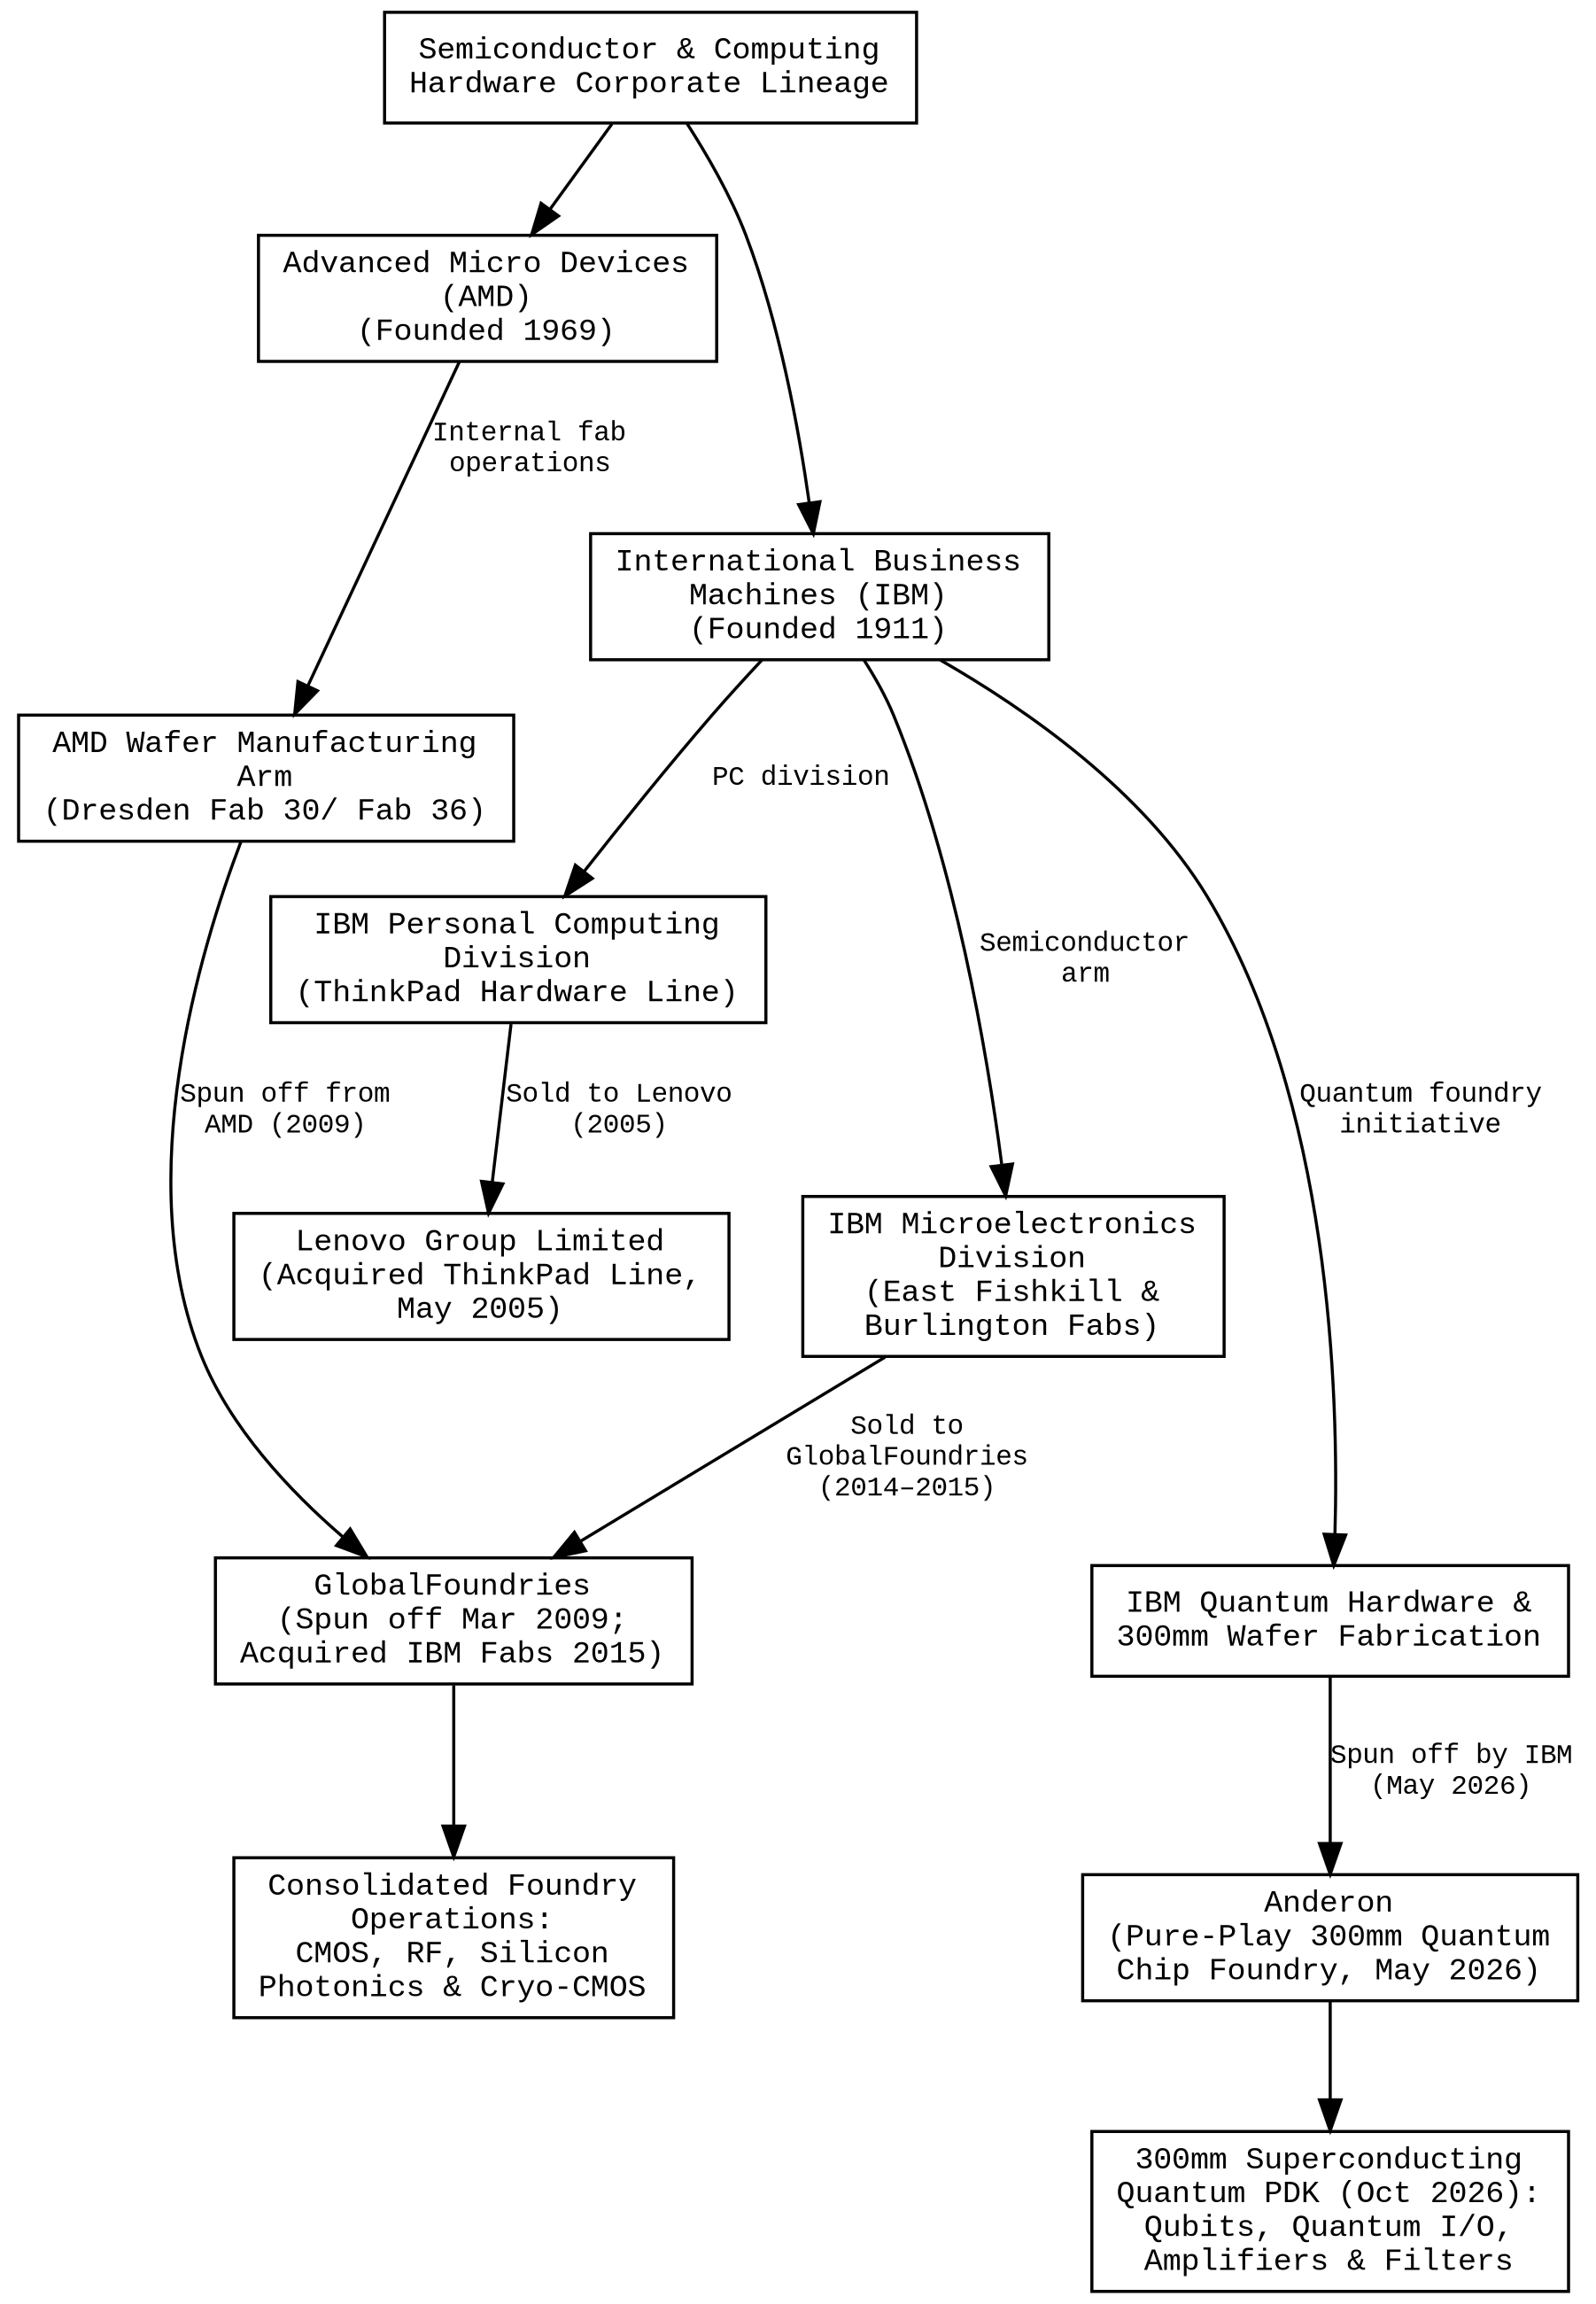

In [3]:
!uv pip install graphviz ipython

"""This script constructs a staggered Graphviz DAG of AMD and IBM corporate spin-offs and divestitures in-memory.

The graph maps the 2009 spin-off of GlobalFoundries from AMD, the 2014-2015 acquisition of the IBM
Microelectronics division by GlobalFoundries, the 2005 sale of the IBM ThinkPad PC division to Lenovo,
and the 2026 spin-off of IBM's quantum wafer foundry Anderon. Control parameters at the top level
govern resolution, typography, spline routing, and vertical staggering.
"""

import graphviz
from IPython.display import display, Image

# Control Knobs
GRAPH_DPI = "250"
NODE_FONT = "DejaVu Sans"
NODE_FONT_WEIGHT = "normal"
EDGE_ROUTING = "spline"
NODE_SHAPE = "box"
BACKGROUND_COLOR = "white"
FOREGROUND_COLOR = "black"
RANK_DIRECTION = "TB"
MAX_CHARACTERS_PER_LINE = 26
TARGET_ASPECT_RATIO = "1.45"  # Height-to-width ratio for compact portrait proportions
RANK_SEPARATION = "0.50"      # Vertical distance (inches) between consecutive ranks
NODE_SEPARATION = "0.28"      # Horizontal distance (inches) between sibling nodes
BRANCH_STAGGER_STEP = 1       # Vertical rank stagger step across parallel branches


def wrap_text(text: str, max_width: int = MAX_CHARACTERS_PER_LINE) -> str:
    """Wraps text to a specified maximum width, hyphenating oversized strings.

    Args:
        text: The original string input.
        max_width: The maximum allowable characters per line.

    Returns:
        A formatted string featuring newline characters at proper intervals.
    """
    lines = []
    for paragraph in text.split('\n'):
        current_line = ""
        words = paragraph.split()
        for word in words:
            while len(word) > max_width:
                if current_line:
                    lines.append(current_line)
                    current_line = ""
                chunk = word[:max_width - 1] + "-"
                lines.append(chunk)
                word = word[max_width - 1:]

            if current_line:
                if len(current_line) + 1 + len(word) <= max_width:
                    current_line += " " + word
                else:
                    lines.append(current_line)
                    current_line = word
            else:
                current_line = word
        if current_line:
            lines.append(current_line)
    return '\n'.join(lines)


def build_corporate_lineage_dag() -> graphviz.Digraph:
    """Constructs the directed Graphviz DAG mapping AMD, IBM, GlobalFoundries, Lenovo, and Anderon."""
    dag = graphviz.Digraph(name='Corporate_SpinOff_Lineage', format='png')

    dag.attr(
        dpi=GRAPH_DPI,
        splines=EDGE_ROUTING,
        bgcolor=BACKGROUND_COLOR,
        rankdir=RANK_DIRECTION,
        ranksep=RANK_SEPARATION,
        nodesep=NODE_SEPARATION,
        ratio=TARGET_ASPECT_RATIO
    )
    dag.attr(
        'node',
        shape=NODE_SHAPE,
        style='solid',
        color=FOREGROUND_COLOR,
        fontcolor=FOREGROUND_COLOR,
        fontname=NODE_FONT,
        fontsize='10'
    )
    dag.attr(
        'edge',
        color=FOREGROUND_COLOR,
        arrowhead='normal',
        fontname=NODE_FONT,
        fontsize='9'
    )

    # Root Node
    dag.node(
        'Root',
        wrap_text('Semiconductor & Computing Hardware Corporate Lineage')
    )

    # Primary Corporate Parents
    dag.node(
        'AMD',
        wrap_text('Advanced Micro Devices (AMD)\n(Founded 1969)')
    )
    dag.node(
        'IBM',
        wrap_text('International Business Machines (IBM)\n(Founded 1911)')
    )

    dag.edge('Root', 'AMD', minlen=str(1 * BRANCH_STAGGER_STEP))
    dag.edge('Root', 'IBM', minlen=str(2 * BRANCH_STAGGER_STEP))

    # AMD Manufacturing Branch -> GlobalFoundries
    dag.node(
        'AMD_Fab',
        wrap_text('AMD Wafer Manufacturing Arm\n(Dresden Fab 30/ Fab 36)')
    )
    dag.edge(
        'AMD',
        'AMD_Fab',
        label=wrap_text('Internal fab operations', 16),
        minlen='1'
    )

    # IBM Division Branches (Staggered Vertically)
    dag.node(
        'IBM_PC',
        wrap_text('IBM Personal Computing Division\n(ThinkPad Hardware Line)')
    )
    dag.node(
        'IBM_Micro',
        wrap_text('IBM Microelectronics Division\n(East Fishkill & Burlington Fabs)')
    )
    dag.node(
        'IBM_Quantum',
        wrap_text('IBM Quantum Hardware &\n300mm Wafer Fabrication')
    )

    dag.edge(
        'IBM',
        'IBM_PC',
        label=wrap_text('PC division', 14),
        minlen=str(1 * BRANCH_STAGGER_STEP)
    )
    dag.edge(
        'IBM',
        'IBM_Micro',
        label=wrap_text('Semiconductor arm', 16),
        minlen=str(2 * BRANCH_STAGGER_STEP)
    )
    dag.edge(
        'IBM',
        'IBM_Quantum',
        label=wrap_text('Quantum foundry initiative', 16),
        minlen=str(3 * BRANCH_STAGGER_STEP)
    )

    # Destination/ Spin-Off Entities
    dag.node(
        'Lenovo',
        wrap_text('Lenovo Group Limited\n(Acquired ThinkPad Line, May 2005)')
    )
    dag.node(
        'GlobalFoundries',
        wrap_text('GlobalFoundries\n(Spun off Mar 2009; Acquired IBM Fabs 2015)')
    )
    dag.node(
        'Anderon',
        wrap_text('Anderon\n(Pure-Play 300mm Quantum Chip Foundry, May 2026)')
    )

    # Edges to Destination Entities
    dag.edge(
        'IBM_PC',
        'Lenovo',
        label=wrap_text('Sold to Lenovo (2005)', 16),
        minlen='1'
    )
    dag.edge(
        'AMD_Fab',
        'GlobalFoundries',
        label=wrap_text('Spun off from AMD (2009)', 16),
        minlen='2'
    )
    dag.edge(
        'IBM_Micro',
        'GlobalFoundries',
        label=wrap_text('Sold to GlobalFoundries (2014–2015)', 16),
        minlen='1'
    )
    dag.edge(
        'IBM_Quantum',
        'Anderon',
        label=wrap_text('Spun off by IBM (May 2026)', 16),
        minlen='1'
    )

    # Downstream Technical Offerings/ Leaves
    dag.node(
        'GF_Portfolio',
        wrap_text('Consolidated Foundry Operations:\nCMOS, RF, Silicon Photonics & Cryo-CMOS')
    )
    dag.node(
        'Anderon_PDK',
        wrap_text('300mm Superconducting Quantum PDK (Oct 2026):\nQubits, Quantum I/O, Amplifiers & Filters')
    )

    dag.edge('GlobalFoundries', 'GF_Portfolio', minlen='1')
    dag.edge('Anderon', 'Anderon_PDK', minlen='1')

    return dag


def display_graph(tree: graphviz.Digraph) -> None:
    """Renders the Graphviz Digraph in memory and displays the PNG without HTML wrappers."""
    binary_png = tree.pipe(format='png')
    display(Image(data=binary_png))


if __name__ == '__main__':
    lineage_dag = build_corporate_lineage_dag()
    display_graph(lineage_dag)